In [1]:
import h5py
import pylab as plt
import numpy as np
from matplotlib.dates import num2date
from datetime import datetime
import pytz

# Load Samples Data

In [2]:
hdf_samples = h5py.File('../data/validation/csextent_samples.h5')
print(hdf_samples.keys())
lat_extent_samples = hdf_samples['lat_extent'][:].squeeze()
times_d2n = hdf_samples['times_d2n'][:]
hdf_samples.close()

<KeysViewHDF5 ['contexts', 'lat_extent', 'lat_max', 'lat_min', 'lats', 'lons', 'radius', 'times_d2n']>


In [3]:
lat_extent_samples.shape

(2748,)

In [4]:
times_samples = np.array(num2date(times_d2n))

# Load Training Data

In [5]:
hdf_samples = h5py.File('../data/validation/csextent_testdata.h5')
print(hdf_samples.keys())
lat_extent_testdata = hdf_samples['lat_extent'][:].squeeze()
times_d2n = hdf_samples['times_d2n'][:]
times_testdata = np.array(num2date(times_d2n))
hdf_samples.close()

<KeysViewHDF5 ['augmentation_index', 'lat_extent', 'lat_max', 'lat_min', 'lats', 'lons', 'polarity_inversion_applied', 'radius', 'realization_index', 'times_d2n']>


In [6]:
lat_extent_testdata.shape

(5496,)

# Plot Experiment

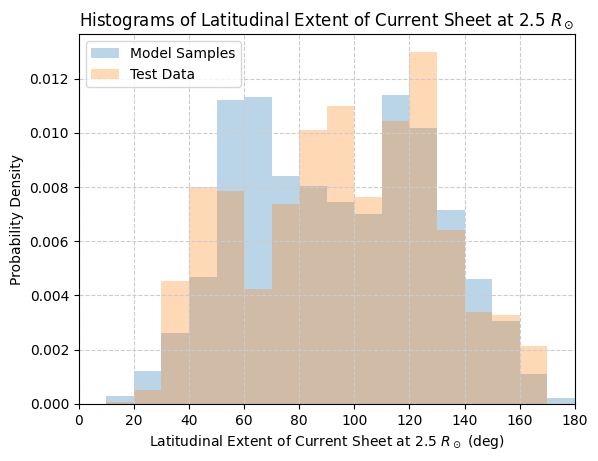

In [7]:
bins = np.arange(0, 181, 10)
cutoff = datetime(2021, 1, 1).replace(tzinfo=pytz.utc)

plt.hist(lat_extent_samples[times_samples < cutoff], bins=bins, label='Model Samples', alpha=0.3, density=True)
plt.hist(lat_extent_testdata[times_testdata < cutoff], bins=bins, label='Test Data', alpha=0.3, density=True)

plt.legend()
plt.ylabel('Probability Density')
plt.xlabel(r'Latitudinal Extent of Current Sheet at 2.5 $R_\odot$ (deg)')
plt.title('Histograms of Latitudinal Extent of Current Sheet at 2.5 $R_\odot$')
plt.xlim(0, 180)
plt.grid(linestyle='dashed', color='#ccc')
plt.savefig('../plots/paper/csextent.png', dpi=300)

In [8]:
print('Samples')
print('---------')
print('Mean %.1f' % np.mean(lat_extent_samples[times_samples < cutoff]))
print('STD %.1f' % np.std(lat_extent_samples[times_samples < cutoff]))
print()
print('Test Data')
print('---------')
print('Mean %.1f'% np.mean(lat_extent_testdata[times_testdata < cutoff]))
print('STD %.1f'%  np.std(lat_extent_testdata[times_testdata < cutoff]))
print()

Samples
---------
Mean 93.6
STD 34.0

Test Data
---------
Mean 95.5
STD 34.1

